# Etap 1 — LeNet-5 + CIFAR-10 + Temperature Scaling

Odtworzenie fragmentu badania z *On Calibration of Modern Neural Networks* (Guo et al., 2017):
- trening **LeNet-5** na **CIFAR-10** (podział 45k / 5k / 10k),
- metryki kalibracji (**ECE**, MCE, NLL) przed kalibracją,
- **temperature scaling** (jeden skalar T) na zbiorze walidacyjnym,
- ponowna ewaluacja + reliability diagrams.

Notatnik jest przeznaczony do uruchomienia przez połączenie z **Google Colab** (rozszerzenie VS Code). Wyniki trafiają do katalogu `outputs/` obok tego pliku.


## 1. Konfiguracja środowiska


In [19]:
import json
import os
import random
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

try:
    from google.colab import drive  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# Przy Colab Extension ustaw katalog roboczy na folder notatnika (jeśli znany).
NOTEBOOK_DIR = Path.cwd()
if IN_COLAB:
    # Opcjonalnie, gdy cwd != katalog notatnika:
    # NOTEBOOK_DIR = Path('/content/Rozpoznawanie-wzorcow/Etap 1/odtworzenie')
    env_dir = os.environ.get('NOTEBOOK_DIR')
    if env_dir:
        NOTEBOOK_DIR = Path(env_dir)
    elif (NOTEBOOK_DIR / 'etap1.ipynb').exists():
        pass
    else:
        matches = list(Path('/content').glob('**/etap1.ipynb'))
        if matches:
            NOTEBOOK_DIR = matches[0].parent

OUTPUT_DIR = NOTEBOOK_DIR / 'outputs'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
DATA_DIR = NOTEBOOK_DIR / 'data'
DATA_DIR.mkdir(parents=True, exist_ok=True)

SEED = 42
BATCH_SIZE = 128
EPOCHS = 200
LR = 0.01
MOMENTUM = 0.9
WEIGHT_DECAY = 1e-4
ECE_BINS = 15  # jak w Table 1 artykułu
NUM_WORKERS = 2

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Colab: {IN_COLAB}')
print(f'Urządzenie: {device}')
if device.type == 'cuda':
    print(f'GPU: {torch.cuda.get_device_name(0)}')
print(f'NOTEBOOK_DIR: {NOTEBOOK_DIR}')
print(f'OUTPUT_DIR:   {OUTPUT_DIR}')


Colab: True
Urządzenie: cuda
GPU: Tesla T4
NOTEBOOK_DIR: /content
OUTPUT_DIR:   /content/outputs


## 2. Dane CIFAR-10 (45k / 5k / 10k)

Zgodnie z Guo et al. (2017): trening 45 000, walidacja 5 000, test 10 000.


In [20]:
CIFAR10_MEAN = (0.4914, 0.4822, 0.4465)
CIFAR10_STD = (0.2470, 0.2435, 0.2616)

train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(CIFAR10_MEAN, CIFAR10_STD),
])

eval_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(CIFAR10_MEAN, CIFAR10_STD),
])

train_full = datasets.CIFAR10(root=DATA_DIR, train=True, download=True, transform=train_transform)
train_full_eval = datasets.CIFAR10(root=DATA_DIR, train=True, download=False, transform=eval_transform)
test_set = datasets.CIFAR10(root=DATA_DIR, train=False, download=True, transform=eval_transform)

n_train_full = len(train_full)  # 50000
n_val = 5000
n_train = n_train_full - n_val  # 45000

g = torch.Generator().manual_seed(SEED)
perm = torch.randperm(n_train_full, generator=g).tolist()
train_idx, val_idx = perm[:n_train], perm[n_train:]

train_set = Subset(train_full, train_idx)
val_set = Subset(train_full_eval, val_idx)

pin = device.type == 'cuda'
train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS, pin_memory=pin)
val_loader = DataLoader(val_set, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=pin)
test_loader = DataLoader(test_set, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=pin)

print(f'train={len(train_set)}, val={len(val_set)}, test={len(test_set)}')


train=45000, val=5000, test=10000


## 3. LeNet-5 (adaptacja do CIFAR-10)

Oryginalne LeNet-5 (LeCun et al., 1998) jest pod MNIST. Tu: 3 kanały wejścia, wejście 32x32, wyjście 10 klas. Bez BatchNorm.


In [21]:
class LeNet5(nn.Module):
    """LeNet-5 dostosowane do CIFAR-10 (RGB, 32x32)."""

    def __init__(self, num_classes: int = 10):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 6, kernel_size=5)   # 32 -> 28
        self.pool = nn.AvgPool2d(kernel_size=2, stride=2)
        self.conv2 = nn.Conv2d(6, 16, kernel_size=5)  # 14 -> 10
        self.fc1 = nn.Linear(16 * 5 * 5, 120)
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, num_classes)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = torch.flatten(x, 1)
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        return self.fc3(x)  # logits


model = LeNet5().to(device)
n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(model)
print(f'Parametry: {n_params:,}')


LeNet5(
  (conv1): Conv2d(3, 6, kernel_size=(5, 5), stride=(1, 1))
  (pool): AvgPool2d(kernel_size=2, stride=2, padding=0)
  (conv2): Conv2d(6, 16, kernel_size=(5, 5), stride=(1, 1))
  (fc1): Linear(in_features=400, out_features=120, bias=True)
  (fc2): Linear(in_features=120, out_features=84, bias=True)
  (fc3): Linear(in_features=84, out_features=10, bias=True)
)
Parametry: 62,006


## 4. Trening


In [22]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(model.parameters(), lr=LR, momentum=MOMENTUM, weight_decay=WEIGHT_DECAY)
scheduler = optim.lr_scheduler.MultiStepLR(optimizer, milestones=[120, 160], gamma=0.1)


def run_epoch(loader, train: bool):
    model.train(train)
    total_loss, correct, total = 0.0, 0, 0
    ctx = torch.enable_grad() if train else torch.no_grad()
    with ctx:
        for inputs, targets in loader:
            inputs, targets = inputs.to(device), targets.to(device)
            if train:
                optimizer.zero_grad(set_to_none=True)
            logits = model(inputs)
            loss = criterion(logits, targets)
            if train:
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * targets.size(0)
            correct += (logits.argmax(1) == targets).sum().item()
            total += targets.size(0)
    return total_loss / total, correct / total


history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}
best_val_loss = float('inf')
best_path = OUTPUT_DIR / 'lenet5_cifar10_best.pt'

for epoch in range(1, EPOCHS + 1):
    tr_loss, tr_acc = run_epoch(train_loader, train=True)
    va_loss, va_acc = run_epoch(val_loader, train=False)
    scheduler.step()

    history['train_loss'].append(tr_loss)
    history['train_acc'].append(tr_acc)
    history['val_loss'].append(va_loss)
    history['val_acc'].append(va_acc)

    if va_loss < best_val_loss:
        best_val_loss = va_loss
        torch.save(
            {'epoch': epoch, 'model_state': model.state_dict(), 'val_loss': va_loss, 'val_acc': va_acc},
            best_path,
        )

    if epoch == 1 or epoch % 5 == 0 or epoch == EPOCHS:
        print(
            f'Epoch {epoch:02d}/{EPOCHS} | '
            f'train loss={tr_loss:.4f} acc={tr_acc*100:.2f}% | '
            f'val loss={va_loss:.4f} acc={va_acc*100:.2f}%'
        )

try:
    ckpt = torch.load(best_path, map_location=device, weights_only=False)
except TypeError:
    ckpt = torch.load(best_path, map_location=device)
model.load_state_dict(ckpt['model_state'])
print(f"Załadowano najlepszy checkpoint (epoka {ckpt['epoch']}, val_loss={ckpt['val_loss']:.4f})")

with open(OUTPUT_DIR / 'train_history.json', 'w', encoding='utf-8') as f:
    json.dump(history, f, indent=2)


Epoch 01/200 | train loss=2.0575 acc=23.52% | val loss=1.7472 acc=36.38%
Epoch 05/200 | train loss=1.4572 acc=47.34% | val loss=1.3333 acc=51.70%
Epoch 10/200 | train loss=1.2383 acc=55.72% | val loss=1.1594 acc=58.86%
Epoch 15/200 | train loss=1.1318 acc=59.98% | val loss=1.0871 acc=61.60%
Epoch 20/200 | train loss=1.0617 acc=62.27% | val loss=1.0315 acc=63.24%
Epoch 25/200 | train loss=1.0235 acc=63.62% | val loss=0.9578 acc=66.44%
Epoch 30/200 | train loss=0.9950 acc=64.90% | val loss=0.9272 acc=67.66%
Epoch 35/200 | train loss=0.9739 acc=65.55% | val loss=0.9089 acc=68.24%
Epoch 40/200 | train loss=0.9453 acc=66.56% | val loss=0.9511 acc=66.70%
Epoch 45/200 | train loss=0.9427 acc=67.00% | val loss=0.9007 acc=68.30%
Epoch 50/200 | train loss=0.9223 acc=67.42% | val loss=0.8970 acc=68.46%
Epoch 55/200 | train loss=0.9168 acc=67.51% | val loss=0.8870 acc=68.32%
Epoch 60/200 | train loss=0.9012 acc=68.21% | val loss=0.9137 acc=67.50%
Epoch 65/200 | train loss=0.8832 acc=68.81% | val l

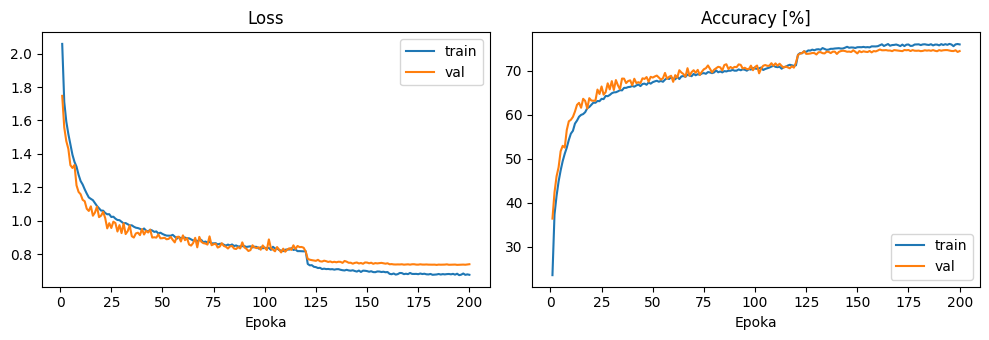

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
epochs_x = range(1, EPOCHS + 1)
axes[0].plot(epochs_x, history['train_loss'], label='train')
axes[0].plot(epochs_x, history['val_loss'], label='val')
axes[0].set_title('Loss')
axes[0].set_xlabel('Epoka')
axes[0].legend()
axes[1].plot(epochs_x, [a * 100 for a in history['train_acc']], label='train')
axes[1].plot(epochs_x, [a * 100 for a in history['val_acc']], label='val')
axes[1].set_title('Accuracy [%]')
axes[1].set_xlabel('Epoka')
axes[1].legend()
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'training_curves.png', dpi=150, bbox_inches='tight')
plt.show()


## 5. Metryki kalibracji (ECE, MCE, NLL)

Zgodnie z definicjami z artykułu (wzory 3, 5, 6). Confidence = max prawdopodobieństwa softmax.


=== Test PRZED kalibracją (T=1) ===
Accuracy: 74.06%
NLL:      0.7561
ECE:      2.91%
MCE:      18.89%


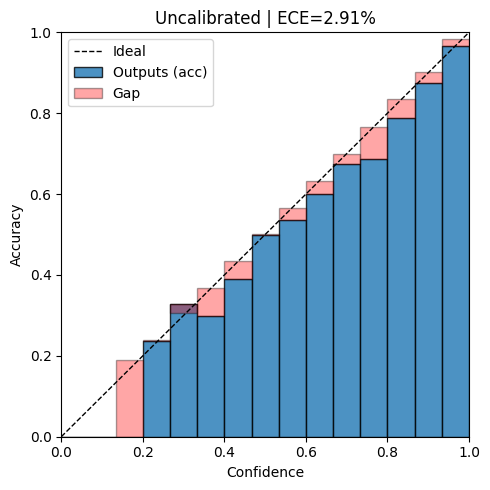

In [24]:
@torch.no_grad()
def collect_logits_labels(loader):
    model.eval()
    logits_list, labels_list = [], []
    for inputs, targets in loader:
        inputs = inputs.to(device)
        logits_list.append(model(inputs).cpu())
        labels_list.append(targets)
    return torch.cat(logits_list), torch.cat(labels_list)


def apply_temperature(logits: torch.Tensor, temperature: float) -> torch.Tensor:
    return logits / temperature


def nll_from_logits(logits: torch.Tensor, labels: torch.Tensor) -> float:
    return F.cross_entropy(logits, labels, reduction='mean').item()


def accuracy_from_logits(logits: torch.Tensor, labels: torch.Tensor) -> float:
    return (logits.argmax(1) == labels).float().mean().item()


def calibration_bins(logits: torch.Tensor, labels: torch.Tensor, n_bins: int = ECE_BINS):
    """Zwraca acc/conf/counts per bin oraz ECE i MCE."""
    probs = F.softmax(logits, dim=1)
    confidences, predictions = probs.max(dim=1)
    accuracies = predictions.eq(labels).float()

    bin_boundaries = torch.linspace(0, 1, n_bins + 1)
    ece, mce = 0.0, 0.0
    bin_acc, bin_conf, bin_count = [], [], []

    for i in range(n_bins):
        lo, hi = bin_boundaries[i].item(), bin_boundaries[i + 1].item()
        # jak w artykule: I_m = ((m-1)/M, m/M]
        if i == 0:
            in_bin = (confidences >= lo) & (confidences <= hi)
        else:
            in_bin = (confidences > lo) & (confidences <= hi)
        count = int(in_bin.sum().item())
        if count > 0:
            acc = accuracies[in_bin].mean().item()
            conf = confidences[in_bin].mean().item()
            gap = abs(acc - conf)
            ece += (count / len(confidences)) * gap
            mce = max(mce, gap)
        else:
            acc, conf = float('nan'), float('nan')
        bin_acc.append(acc)
        bin_conf.append(conf)
        bin_count.append(count)

    return {
        'ece': ece,
        'mce': mce,
        'bin_acc': bin_acc,
        'bin_conf': bin_conf,
        'bin_count': bin_count,
        'bin_boundaries': bin_boundaries.tolist(),
    }


def evaluate(logits: torch.Tensor, labels: torch.Tensor, temperature: float = 1.0) -> dict:
    scaled = apply_temperature(logits, temperature)
    cal = calibration_bins(scaled, labels, ECE_BINS)
    return {
        'temperature': temperature,
        'accuracy': accuracy_from_logits(scaled, labels),
        'nll': nll_from_logits(scaled, labels),
        'ece': cal['ece'],
        'mce': cal['mce'],
        'calibration': cal,
    }


def plot_reliability(cal: dict, title: str, path: Path):
    n_bins = len(cal['bin_acc'])
    centers = [(cal['bin_boundaries'][i] + cal['bin_boundaries'][i + 1]) / 2 for i in range(n_bins)]
    width = 1.0 / n_bins
    accs = [0.0 if np.isnan(a) else a for a in cal['bin_acc']]
    confs = [0.0 if np.isnan(c) else c for c in cal['bin_conf']]
    gaps = [abs(a - c) for a, c in zip(accs, confs)]

    fig, ax = plt.subplots(figsize=(5, 5))
    ax.bar(centers, accs, width=width, edgecolor='black', alpha=0.8, label='Outputs (acc)')
    ax.bar(
        centers,
        gaps,
        width=width,
        bottom=[min(a, c) for a, c in zip(accs, confs)],
        edgecolor='black',
        alpha=0.35,
        color='red',
        label='Gap',
    )
    ax.plot([0, 1], [0, 1], 'k--', linewidth=1, label='Ideal')
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_xlabel('Confidence')
    ax.set_ylabel('Accuracy')
    ax.set_title(title)
    ax.legend(loc='upper left')
    fig.tight_layout()
    fig.savefig(path, dpi=150, bbox_inches='tight')
    plt.show()


val_logits, val_labels = collect_logits_labels(val_loader)
test_logits, test_labels = collect_logits_labels(test_loader)

uncal_test = evaluate(test_logits, test_labels, temperature=1.0)
print('=== Test PRZED kalibracją (T=1) ===')
print(f"Accuracy: {uncal_test['accuracy']*100:.2f}%")
print(f"NLL:      {uncal_test['nll']:.4f}")
print(f"ECE:      {uncal_test['ece']*100:.2f}%")
print(f"MCE:      {uncal_test['mce']*100:.2f}%")

plot_reliability(
    uncal_test['calibration'],
    title=f"Uncalibrated | ECE={uncal_test['ece']*100:.2f}%",
    path=OUTPUT_DIR / 'reliability_uncalibrated.png',
)


## 6. Temperature scaling

Jeden parametr T > 0. Skalowane logits: z/T, potem softmax. T optymalizujemy względem **NLL na walidacji**. Predykcje klas się nie zmieniają.


Optymalne T (val NLL): 1.1309

=== Test PO temperature scaling ===
Accuracy: 74.06%  (bez zmian względem uncalib.)
NLL:      0.7486
ECE:      1.02%
MCE:      4.48%


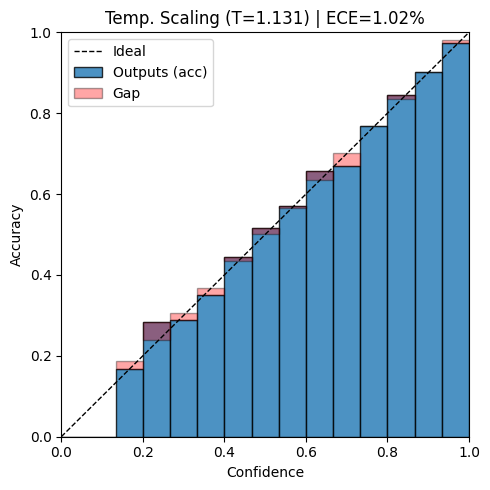

In [25]:
def fit_temperature(logits: torch.Tensor, labels: torch.Tensor) -> float:
    """Optymalizacja T przez LBFGS na NLL (walidacja)."""
    raw = nn.Parameter(torch.ones(1))
    opt = optim.LBFGS([raw], lr=0.01, max_iter=50, line_search_fn='strong_wolfe')

    def _T():
        return F.softplus(raw) + 1e-6

    def closure():
        opt.zero_grad(set_to_none=True)
        loss = F.cross_entropy(logits / _T(), labels)
        loss.backward()
        return loss

    opt.step(closure)
    with torch.no_grad():
        T = float(_T().item())
    return T


T_opt = fit_temperature(val_logits, val_labels)
print(f'Optymalne T (val NLL): {T_opt:.4f}')

cal_test = evaluate(test_logits, test_labels, temperature=T_opt)
print()
print('=== Test PO temperature scaling ===')
print(f"Accuracy: {cal_test['accuracy']*100:.2f}%  (bez zmian względem uncalib.)")
print(f"NLL:      {cal_test['nll']:.4f}")
print(f"ECE:      {cal_test['ece']*100:.2f}%")
print(f"MCE:      {cal_test['mce']*100:.2f}%")

plot_reliability(
    cal_test['calibration'],
    title=f"Temp. Scaling (T={T_opt:.3f}) | ECE={cal_test['ece']*100:.2f}%",
    path=OUTPUT_DIR / 'reliability_temperature_scaling.png',
)


## 7. Podsumowanie i zapis wyników

Dla porównania: w Table 1 artykułu dla CIFAR-10 / LeNet-5: ECE uncalib. **3.02%**, po Temp. Scaling **0.93%**. Przy domyślnych hiperparametrach treningu wartości mogą się różnić — celem jest poprawna implementacja metody.


In [26]:
results = {
    'paper_reference': {
        'title': 'On Calibration of Modern Neural Networks (Guo et al., 2017)',
        'setting': 'CIFAR-10 / LeNet-5 / Temperature Scaling',
        'paper_ece_uncalibrated_percent': 3.02,
        'paper_ece_temp_scaling_percent': 0.93,
        'ece_bins': ECE_BINS,
    },
    'training': {
        'epochs': EPOCHS,
        'batch_size': BATCH_SIZE,
        'optimizer': 'SGD',
        'lr': LR,
        'momentum': MOMENTUM,
        'weight_decay': WEIGHT_DECAY,
        'seed': SEED,
        'best_checkpoint_epoch': int(ckpt['epoch']),
        'best_val_loss': float(ckpt['val_loss']),
        'best_val_acc': float(ckpt['val_acc']),
    },
    'temperature': T_opt,
    'test_uncalibrated': {
        'accuracy': uncal_test['accuracy'],
        'nll': uncal_test['nll'],
        'ece': uncal_test['ece'],
        'mce': uncal_test['mce'],
        'ece_percent': uncal_test['ece'] * 100,
        'mce_percent': uncal_test['mce'] * 100,
    },
    'test_temperature_scaling': {
        'accuracy': cal_test['accuracy'],
        'nll': cal_test['nll'],
        'ece': cal_test['ece'],
        'mce': cal_test['mce'],
        'ece_percent': cal_test['ece'] * 100,
        'mce_percent': cal_test['mce'] * 100,
    },
}

results_path = OUTPUT_DIR / 'results.json'
with open(results_path, 'w', encoding='utf-8') as f:
    json.dump(results, f, indent=2)

torch.save(
    {
        'val_logits': val_logits,
        'val_labels': val_labels,
        'test_logits': test_logits,
        'test_labels': test_labels,
        'T': T_opt,
    },
    OUTPUT_DIR / 'logits.pt',
)

print('Zapisano:')
for p in sorted(OUTPUT_DIR.iterdir()):
    print(f'  - {p.name} ({p.stat().st_size} B)')

print()
print('--- Skrót ---')
print(f'T* = {T_opt:.4f}')
print(f"ECE  uncalib. -> temp. scaling: {uncal_test['ece']*100:.2f}% -> {cal_test['ece']*100:.2f}%")
print(f"NLL  uncalib. -> temp. scaling: {uncal_test['nll']:.4f} -> {cal_test['nll']:.4f}")
print(f"Acc (bez zmian): {cal_test['accuracy']*100:.2f}%")
print(f'Plik wyników: {results_path}')


Zapisano:
  - lenet5_cifar10_best.pt (252357 B)
  - logits.pt (722131 B)
  - reliability_temperature_scaling.png (45958 B)
  - reliability_uncalibrated.png (44639 B)
  - results.json (1063 B)
  - train_history.json (16526 B)
  - training_curves.png (70062 B)

--- Skrót ---
T* = 1.1309
ECE  uncalib. -> temp. scaling: 2.91% -> 1.02%
NLL  uncalib. -> temp. scaling: 0.7561 -> 0.7486
Acc (bez zmian): 74.06%
Plik wyników: /content/outputs/results.json


## 8. Pakowanie wyników

Spakowanie zawartości `outputs/` do archiwum ZIP (wygodne do pobrania z Colab).

In [27]:
import shutil
from datetime import datetime

stamp = datetime.now().strftime('%Y%m%d_%H%M%S')
zip_base = NOTEBOOK_DIR / f'outputs_{stamp}'
zip_path = Path(shutil.make_archive(str(zip_base), 'zip', root_dir=OUTPUT_DIR))

print(f'Utworzono: {zip_path}')
print(f'Rozmiar:   {zip_path.stat().st_size / 1024:.1f} KiB')
print('Zawartość archiwum:')
for p in sorted(OUTPUT_DIR.iterdir()):
    if p.is_file():
        print(f'  - {p.name}')

Utworzono: /content/outputs_20261109_231949.zip
Rozmiar:   935.0 KiB
Zawartość archiwum:
  - lenet5_cifar10_best.pt
  - logits.pt
  - reliability_temperature_scaling.png
  - reliability_uncalibrated.png
  - results.json
  - train_history.json
  - training_curves.png
